[([[np.int32(78), np.int32(20)], [np.int32(132), np.int32(20)], [np.int32(132), np.int32(94)], [np.int32(78), np.int32(94)]], '1', np.float64(0.5369391571471205))]
[np.int32(84), 179, np.int32(73), np.int32(132)]
(28, 28)


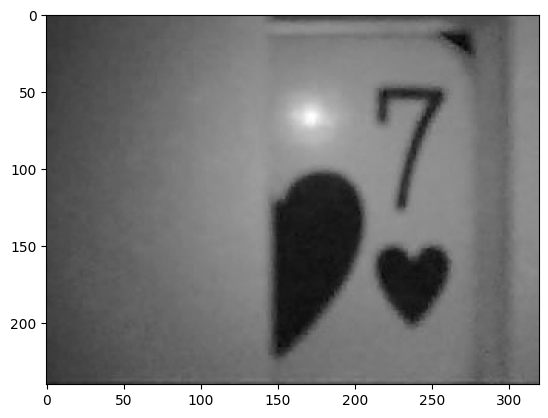

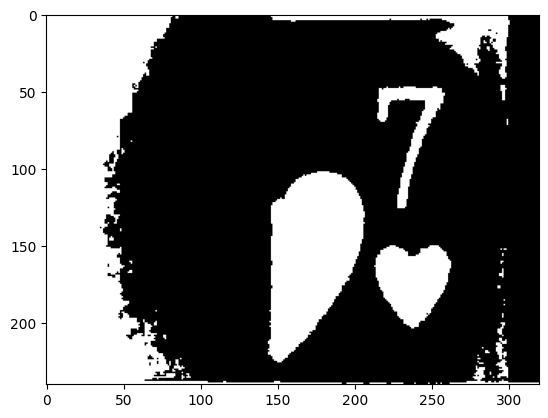

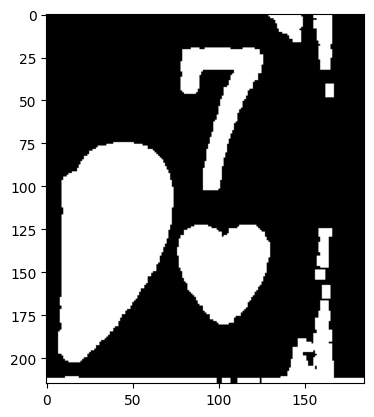

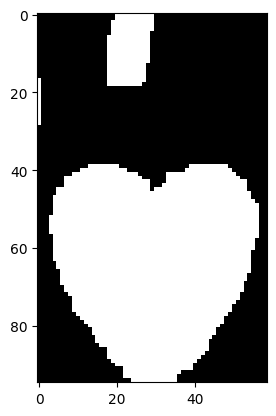

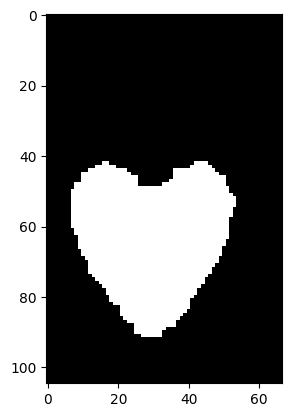

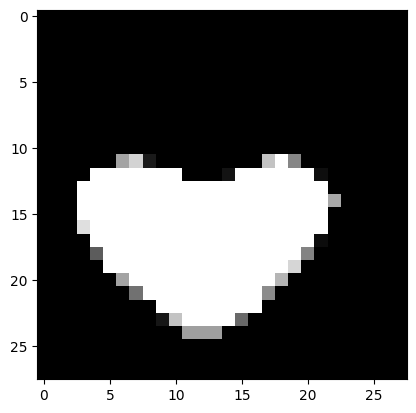

In [95]:
import easyocr
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plot
import math

reader=easyocr.Reader(['en'])
im=cv.imread("7.jpg")
ig=cv.cvtColor(im,cv.COLOR_RGB2GRAY)


# ig = cv.filter2D(ig, -1, kernel)
# ig=cv.blur(ig,(11,11))
plot.figure()
plot.imshow(ig,cmap="gray")
# ig=cv.adaptiveThreshold(ig,255,cv.ADAPTIVE_THRESH_MEAN_C,cv.THRESH_BINARY_INV,7,4)
ret,ig=cv.threshold(ig,0,255,cv.THRESH_BINARY_INV+cv.THRESH_OTSU)
plot.figure()
plot.imshow(ig,cmap="gray")
# ia=ig[:150,150:]

kernel=np.ones((5,5),np.uint8)
ig=cv.dilate(ig,kernel,iterations=1)

# kernel = np.ones((5,5),np.uint8)



ig=ig[25:,(int)(0.625*im.shape[0])-15:]
plot.figure()
plot.imshow(ig,cmap="gray")



# plot.figure()
# plot.imshow(thresh,cmap="gray")

a=reader.readtext(ig,allowlist='0123456789KJQA')

print(a)
minX=a[0][0][0][0]
maxX=a[0][0][1][0]
maxY=a[0][0][2][1]
minY=max(maxY-10,0)
minX=max(0,minX-5)
maxY=min(maxY*1.7+20,ig.shape[0])
maxY=int(maxY)
print([minY,maxY,minX,maxX])
thresh=ig[minY:maxY,minX:maxX]
plot.figure()
plot.imshow(thresh,cmap="gray")
cnts,x = cv.findContours(thresh, cv.RETR_LIST, cv.CHAIN_APPROX_SIMPLE)
cntsAreas=[(cv.contourArea(i),i) for i in cnts]
suit=max(cntsAreas, key=lambda x: x[0])[1]
x,y,w,h=cv.boundingRect(suit)
thresh=np.zeros((y+h+10,x+w+10),dtype=np.uint8)
cv.drawContours(thresh,[suit],-1,(255,255,255),-1)
kernel=np.ones((3,3),np.uint8)
# thresh=cv.blur(thresh,(3,3))
thresh=cv.erode(thresh,kernel,iterations=3)
plot.figure()
plot.imshow(thresh,cmap="gray")
thresh=cv.resize(thresh,(28,28))
plot.figure()
plot.imshow(thresh,cmap="gray")
cv.imwrite("test.jpg",thresh)
print(thresh.shape)


